In [35]:
#Input Libraries 

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm  
from sklearn.linear_model import LassoCV, Lasso, RidgeCV, Ridge, ElasticNetCV, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error  
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Import External Source Data 

df=pd.read_csv("C:\\Users\\NWILS\\.vscode\\Lesson_03_Supervised_Learning_ Regression_and_its_Application\\housing.csv")
dft=pd.read_csv("C:\\Users\\NWILS\\.vscode\\Lesson_03_Supervised_Learning_ Regression_and_its_Application\\housing.csv")

df.info()
print(df.describe())
print(df.shape)
df.head()

df.isnull().sum()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5)
memory usage: 1.4 MB
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861           28.639486   2635.763081   
std        2.003532      2.135952           12.585558   2181.615252   
min     -124.350000

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
dtype: int64

In [ ]:
#Setup Linear Regression Analysis (Income VS Home Prices)

#Dependent Variable (Y) - Home Prices

y = df["median_house_value"]

#Independent Variable [[]] double brackets means you are selecting a dataframe instead of a series (dataframe is the container for multiple columns). [] brackets means you are selecting a series instead of a dataframe (series is the container for a single column).

x = df[["median_income"]] #adjust upper or lower case "x" depending on whether you are using the training or testing data.

#Split Data (use upper case X for training, and lower case x for testing) - 70% training data, 30% testing data, random_state number is basically a unique ID that lets Python know how it split the data in case you need to go back and attempt to recreate your process or share your results with someone else. 
X_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

#Add data to Linear Regression Model 
X_train_sm = sm.add_constant(X_train) #add constant to the training data
x_test_sm = sm.add_constant(x_test) #add constant to the testing data

#Factor In Regularition
scaler= StandardScaler()
X_train_s= scaler.fit_transform(X_train_sm)
x_test_s = scaler.transform (x_test_sm)

lin_reg = sm.OLS(y_train, X_train_s).fit() #fit the model to the training data (ordinary linear squared)
print(lin_reg.summary()) #print the summary of the model

#prediction on test data x_test_sum = sm.add_constant(x_test) #add constant to the testing data
y_pred = lin_reg.predict(x_test_s)
print(y_pred)

#Test Metrics 
print("\nTest R2:", r2_score(y_test, y_pred))
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))


#Ridge Regression Model(0)

ridge= Ridge(alpha=10, max_iter = 30000, random_state=12)
ridge.fit(X_train_s, y_train)

ridge_pred=ridge.predict(x_test_s)

#Comparing Metrics (test to Ridge Model)--Look for the lowest RMSE while maintaining the highest R2
print("\nTest R2 Compare2:", r2_score(y_test, ridge_pred))
print("Test MSE Compare2:", mean_squared_error(y_test, ridge_pred))
print("Test MAE Compare2:", mean_absolute_error(y_test, ridge_pred))

#Determining the best ALPHA to use in the model comparsion using K-Fold

KF=KFold(n_splits=10, shuffle=True, random_state=42)

ridge_cv_model= RidgeCV(
    alphas=np.logspace(-4,4,100),
    cv=KF,
    max_iter=50000,
    n_jobs=-1,
    random_state=42
).fit(X_train_s, y_train)

#Identifying Best Alpha 
best_alphas=ridge_cv_model.alpha_

#Adding best Alpha back to the Model
ridge_best=Lasso(alpha=best_alphas, max_iter=50000, random_state=42)
ridge_best.fit(X_train_s, y_train)

#Determine the y-prediction using the best alpha 
prediction=ridge_best.predict(x_test_s)

#Comparing Metrics (test to Lasso Model)--Look for the lowest RMSE while maintaining the highest R2 
print("\nTest R2 Best Ridge:", r2_score(y_test,prediction))
print("Test MSE Best Ridge:", mean_squared_error(y_test,prediction))
print("Test MAE Best Ridge:", mean_absolute_error(y_test,prediction))

#Viewing the coefficient w/ the best Alpha 
coef_series=pd.Series(ridge_best.coef_, index=X_train.columns)
print(coef_series.sort_values(key=np.abs, ascending=False))


#Lasso Regression Model (1)
lasso= Lasso(alpha=10, max_iter = 30000, random_state=12)
lasso.fit(X_train_s, y_train)

lasso_pred=lasso.predict(x_test_s)

#Comparing Metrics (test to Lasso Model)--Look for the lowest RMSE while maintaining the highest R2
print("\nTest R2 Compare:", r2_score(y_test, lasso_pred))
print("Test MSE Compare:", mean_squared_error(y_test, lasso_pred))
print("Test MAE Compare:", mean_absolute_error(y_test, lasso_pred))

#Determining the best ALPHA to use in the model comparsion using K-Fold

KF=KFold(n_splits=10, shuffle=True, random_state=42)

lasso_cv_model= LassoCV(
    alphas=np.logspace(-4,4,100),
    cv=KF,
    max_iter=50000,
    n_jobs=-1,
    random_state=42
).fit(X_train_s, y_train)

#Identifying Best Alpha 
best_alpha=lasso_cv_model.alpha_

#Adding best Alpha back to the Model
lasso_best=Lasso(alpha=best_alpha, max_iter=50000, random_state=42)
lasso_best.fit(X_train_s, y_train)

#Determine the y-prediction using the best alpha 
pred=lasso_best.predict(x_test_s)

#Comparing Metrics (test to Lasso Model)--Look for the lowest RMSE while maintaining the highest R2 
print("\nTest R2 Best Lasso:", r2_score(y_test,pred))
print("Test MSE Best Lasso:", mean_squared_error(y_test,pred))
print("Test MAE Best Lasso:", mean_absolute_error(y_test,pred))

#Viewing the coefficient w/ the best Alpha 
coef_series=pd.Series(lasso_best.coef_, index=X_train.columns)
print(coef_series.sort_values(key=np.abs, ascending=False))


#Elastic Net Regression 

Elasnet= Elastic(alpha=10, max_iter = 30000, random_state=12)
elasticnet.fit(X_train_s, y_train)

elasticnet_pred=elasticnet.predict(x_test_s)

#Comparing Metrics (test to Elastic Net Model)--Look for the lowest RMSE while maintaining the highest R2
print("\nTest R2 Compare:", r2_score(y_test, elasticnet_pred))
print("Test MSE Compare:", mean_squared_error(y_test, elasticnet_pred))
print("Test MAE Compare:", mean_absolute_error(y_test, elasticnet_pred))

#Determining the best ALPHA to use in the model comparsion using K-Fold

KF=KFold(n_splits=10, shuffle=True, random_state=42)

ElasticNet_cv_model= ElasticNetCV(
    alphas=np.logspace(-4,4,100),
    cv=KF,
    max_iter=50000,
    n_jobs=-1,
    random_state=42
).fit(X_train_s, y_train)

#Identifying Best Alpha 
best_alphal=ElasticNet_cv_model.alpha_

#Adding best Alpha back to the Model
elastic_best=Elastic(alpha=best_alphal, max_iter=50000, random_state=42)
elastic_best.fit(X_train_s, y_train)

#Determine the y-prediction using the best alpha 
predictions=Elastic_best.predict(x_test_s)

#Comparing Metrics (test to Elastic Model)--Look for the lowest RMSE while maintaining the highest R2 
print("\nTest R2 Best Elastic:", r2_score(y_test,predictions))
print("Test MSE Best Elastic:", mean_squared_error(y_test,predictions))
print("Test MAE Best Elastic:", mean_absolute_error(y_test,predictions))

#Viewing the coefficient w/ the best Alpha 
coef_series=pd.Series(elastic_best.coef_, index=X_train.columns)
print(coef_series.sort_values(key=np.abs, ascending=False))




C:\Users\NWILS\AppData\Local\Temp\ipykernel_14312\2348348218.py:23: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin_reg = sm.OLS(y_train, X_train_s).fit() #fit the model to the training data (ordinary linear squared)


                                 OLS Regression Results                                
Dep. Variable:     median_house_value   R-squared (uncentered):                   0.113
Model:                            OLS   Adj. R-squared (uncentered):              0.113
Method:                 Least Squares   F-statistic:                              1838.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):                        0.00
Time:                        23:44:29   Log-Likelihood:                     -1.9845e+05
No. Observations:               14448   AIC:                                  3.969e+05
Df Residuals:                   14447   BIC:                                  3.969e+05
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

TypeError: _BaseRidgeCV.__init__() got an unexpected keyword argument 'max_iter'

C:\Users\NWILS\AppData\Local\Temp\ipykernel_14312\3182938587.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_line = lin_reg.params[0] + lin_reg.params[1] * X_line #calculate the corresponding y values for the line


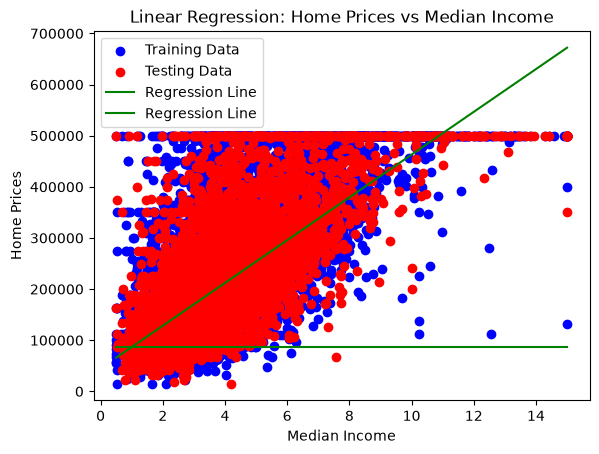

In [5]:
#simple linear visual 

X_line= np.linspace(X["median_income"].min(), X["median_income"].max(), 100) #create a line of 100 points between the min and max values of the independent variable   
X_line= sm.add_constant(X_line) #add constant to the line
y_line = lin_reg.params[0] + lin_reg.params[1] * X_line #calculate the corresponding y values for the line

plt.figure()
plt.scatter(X_train["median_income"], y_train, color="blue", label="Training Data") #plot the training data
plt.scatter(x_test["median_income"], y_test, color="red", label="Testing Data")#plot the testing data
plt.plot(X_line[:, 1], y_line, color="green", label="Regression Line") #plot the regression line
plt.xlabel("Median Income") 
plt.ylabel("Home Prices")
plt.title("Linear Regression: Home Prices vs Median Income")
plt.legend()
plt.show()


In [ ]:
#Setup Linear Multiple Regression Analysis (Income VS Home Prices)

#Dependent Variable (Y) - Home Prices

y = dft["median_house_value"]

#Independent Variable [[]] double brackets means you are selecting a dataframe instead of a series (dataframe is the container for multiple columns). [] brackets means you are selecting a series instead of a dataframe (series is the container for a single column).

x = dft.drop(columns=["median_house_value"]) #adjust independent variable to be the dependent variable by dropping the median_income column after import 
#Split Data (use upper case X for training, and lower case x for testing) - 70% training data, 30% testing data, random_state number is basically a unique ID that lets Python know how it split the data in case you need to go back and attempt to recreate your process or share your results with someone else. 

#Drop missing rows (total bedrooms has missing values)-AXIS refers to columns 
#dft=pd.concat([x, y], axis=1).dropna()
#x=dft.drop(columns=["median_house_value"])
#y=dft["median_house_value"]

#Split Data (use upper case X for training, and lower case x for testing) - 70% training data, 30% testing data, random_state number is basically a unique ID that lets Python know how it split the data in case you need to go back and attempt to recreate your process or share your results with someone else. 
X_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

X_train_sm = sm.add_constant(X_train) #add constant to the training data
x_test_sm = sm.add_constant(x_test) #add constant to the testing data   
lin_reg = sm.OLS(y_train, X_train_sm).fit() #fit the model to the training data (ordinary linear squared)
print(lin_reg.summary()) #print the summary of the model

#prediction on test data x_test_sum = sm.add_constant(x_test) #add constant to the testing data
y_pred = lin_reg.predict(x_test_sm)
print(y_pred)


#Test Metrics  
print("Test R2:", r2_score(y_test, y_pred)) #tells you how well the model fits the data (1 is perfect fit, 0 is no fit) y test vs y train 
print("Test MSE2:", mean_squared_error(y_test, y_pred)) #tells you the difference in the squared mean between the test and train data model sets 
print("Test MAE2:", mean_absolute_error(y_test, y_pred)) #tells you the difference in the absolute mean between the test and train data model sets 




                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.637
Model:                            OLS   Adj. R-squared:                  0.637
Method:                 Least Squares   F-statistic:                     3165.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:18:41   Log-Likelihood:            -1.8163e+05
No. Observations:               14448   AIC:                         3.633e+05
Df Residuals:                   14439   BIC:                         3.634e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -3.584e+06   7.45

ValueError: Input contains NaN.